# V0.3 — revisión del aprendizaje temporal
Este notebook muestra la última ejecución completa sin volver a entrenar. Usa el kernel de `V0.2/.venv`.

La tarea es estimar selección de una oferta propia ya enviada, dentro de procesos adjudicados con fechas consistentes. Todo 2024 ya fue explorado: el test es retrospectivo. Un nuevo periodo será necesario para confirmar una mejora.

Para entrenar desde la raíz: `V0.2/.venv/Scripts/python.exe V0.3/modelo_temporal.py`. Consulta `README.md` para el protocolo y sus límites.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
BASE = Path.cwd().resolve()
if not (BASE / 'modelo_temporal.py').exists():
    BASE = BASE / 'V0.3'
if not (BASE / 'modelo_temporal.py').exists():
    raise FileNotFoundError('Abre desde la raíz del proyecto o V0.3.')
sys.path.insert(0, str(BASE))
from modelo_temporal import predict
completas = sorted(p.parent for p in (BASE / 'resultados').glob('*/informe.json') if (p.parent / 'estado_ejecucion.json').exists())
if not completas:
    raise FileNotFoundError('Ejecuta primero modelo_temporal.py con el Python de V0.2.')
RUN = completas[-1]  # Puedes fijar aquí una ejecución concreta.
informe = json.loads((RUN / 'informe.json').read_text(encoding='utf-8'))
config = json.loads((RUN / 'configuracion.json').read_text(encoding='utf-8'))
print('Ejecución:', RUN.name)
display(Markdown((RUN / 'RESULTADO.md').read_text(encoding='utf-8')))

Ejecución: 20261104T161350642485Z


# Resultado V0.3 — candidato exploratorio

Ganador seleccionado en validación: **logistica_proveedor**. Umbral: 0.368052.
Política: precisión máxima con recall ≥ 30% y ≥ 200 alertas en validación.

| Prueba temporal retrospectiva | Precisión | Recall | AP | ROC AUC | Brier |
|---|---:|---:|---:|---:|---:|
| Candidato | 0.1230 | 0.3507 | 0.1240 | 0.5824 | 0.1433 |
| Base con mismo protocolo | 0.1290 | 0.3031 | 0.1202 | 0.5966 | 0.1229 |

Intervalo bootstrap por licitación de diferencia de precisión candidato−base: [-0.05892356778926931, 0.01008389288992407].
Cumple diferencia positiva con IC95 y recall mínimo en test: **False**.
Este indicador no acredita generalización futura. No se promovió ni reemplazó V0.2.

## Límites

- Todo 2024 ya fue explorado: test temporal retrospectivo, no confirmatorio independiente.
- Estado y fecha de adjudicación son proxies; faltan snapshots y fecha verificable de resultado efectivo.
- Los campos del CSV podrían haber cambiado después del envío; no se acredita disponibilidad histórica.
- La población son procesos adjudicados con fechas válidas y resultado disponible al corte, no todas las licitaciones.
- Muestra por licitación y límite de ajuste documentados; no se usó sobremuestreo 50/50.
- Bootstrap condicionado a la muestra y al modelo ajustado: no captura toda la incertidumbre de entrenamiento.
- V0.2 usa otra población y partición: sus métricas no permiten declarar una mejora directa.
- No se construyeron tasas históricas de éxito sin verificar fechas efectivas de adjudicación.


## Población y exclusiones
El muestreo selecciona licitaciones completas por hash, sin balancear etiquetas. Las causas de exclusión pueden solaparse. Se conservan faltantes de montos/cantidades para imputarlos dentro del entrenamiento. Los procesos no adjudicados no se convierten automáticamente en derrotas.

In [2]:
display(pd.DataFrame(informe['particiones']).T)
exclusiones = json.loads((RUN / 'exclusiones.json').read_text(encoding='utf-8'))
display(pd.DataFrame({k:v for k,v in exclusiones.items() if k != 'diagnostico_clave_candidata'}).T)
print('Claves repetidas, sin eliminación automática:', exclusiones['diagnostico_clave_candidata'])
display(pd.DataFrame(config['cortes'], index=['desde_inclusive','hasta_exclusive']).T)

,filas,licitaciones,prevalencia,filas_usadas_ajuste,licitaciones_usadas_ajuste,filas_fuera_por_limite
train,185071.0,9926.0,0.235342,80000.0,4045.0,105071.0
calibracion,17778.0,1424.0,0.247441,NaN,NaN,NaN
validacion,20835.0,1655.0,0.248188,NaN,NaN,NaN
test,178143.0,4959.0,0.092560,NaN,NaN,NaN


,licitaciones,filas
estado_no_adjudicado,13432,209281
etiqueta_invalida,0,0
fecha_invalida,232,785
fecha_incoherente,0,0
texto_corrupto_en_clave,0,0
publicacion_inconsistente,1,4
adjudicacion_inconsistente,233,789
resultado_no_disponible_al_corte,4946,79997
total_excluidas,18378,289278


Claves repetidas, sin eliminación automática: {'campos': ['Codigo', 'Codigoitem', 'CodigoProveedor', 'CodigoSucursalProveedor', 'Correlativo'], 'filas_con_clave_repetida': 15692, 'accion': 'Solo diagnóstico; no se eliminan automáticamente ofertas diferentes'}


,desde_inclusive,hasta_exclusive
train,2024-01-01,2024-06-01
calibracion,2024-06-01,2024-08-01
validacion,2024-08-01,2024-10-01
test,2024-10-01,2025-01-01


## Selección solo en validación
Primero se ajusta con enero–mayo, luego se calibra con junio–julio. Agosto–septiembre elige modelo y umbral para precisión máxima con recall mínimo del 30 % y soporte mínimo. Falta de convergencia excluye un candidato. Las variantes de regresión logística añaden grupos de variables de forma acumulada.

In [3]:
validacion = pd.DataFrame(json.loads((RUN / 'validacion.json').read_text(encoding='utf-8')))
display(validacion[['candidato','precision','recall','average_precision','roc_auc','brier','alertas','umbral','convergio','elegible','segundos']])
display(informe['decision'])
display(validacion[['candidato','advertencias']])

,candidato,precision,recall,average_precision,roc_auc,brier,alertas,umbral,convergio,elegible,segundos
0,logistica_base,0.397341,0.300522,0.354650,0.618531,0.180388,3911,0.324296,True,True,5.380464
1,logistica_producto,0.412108,0.300135,0.368346,0.642238,0.177872,3766,0.357373,True,True,8.102313
2,logistica_proveedor,0.462750,0.318314,0.399822,0.675548,0.173034,3557,0.368052,True,True,16.544582
3,logistica_cantidad_precio,0.462009,0.306904,0.398695,0.673987,0.173233,3435,0.370374,True,True,26.458595
4,arbol_cantidad_precio,0.306405,0.676272,0.287993,0.574973,0.184802,11413,0.256625,True,True,7.455351
5,bosque_cantidad_precio,0.425229,0.305744,0.372850,0.651831,0.176901,3718,0.330631,True,True,9.116902
6,mlp_cantidad_precio,0.319039,0.356798,0.309943,0.592983,0.183791,5783,0.335070,False,False,19.871455


{'candidato': 'logistica_proveedor',
 'umbral': 0.36805237108150896,
 'criterio': 'precisión en validación, recall mínimo y soporte; convergencia requerida',
 'recall_minimo': 0.3,
 'min_alertas': 200,
 'decidido_antes_de_evaluacion_test': True}

,candidato,advertencias
0,logistica_base,[]
1,logistica_producto,[]
2,logistica_proveedor,[]
3,logistica_cantidad_precio,[]
4,arbol_cantidad_precio,[]
5,bosque_cantidad_precio,[]
6,mlp_cantidad_precio,[Stochastic Optimizer: Maximum iterations (100...


## Prueba retrospectiva y cambio temporal
El umbral queda fijado antes de esta evaluación. No reajustarlo para mejorar el resultado mostrado. La base usa la misma población y cortes: las métricas anteriores de V0.2 no son directamente comparables. Un recall mínimo elegido en validación puede incumplirse en test.

,filas,prevalencia,precision,recall,average_precision,roc_auc,brier,log_loss,alertas,cobertura
logistica_proveedor,178143,0.09256,0.123029,0.350719,0.123988,0.582429,0.143258,0.458966,47005,0.263861
logistica_base,178143,0.09256,0.128997,0.303111,0.120161,0.596624,0.122911,0.415433,38745,0.217494
dummy_prior,178143,0.09256,0.0,0.0,0.09256,0.5,0.110048,0.392732,0,0.0


{'logistica_proveedor': {'precision_ic95': [0.06777680935406198,
   0.21000365828061926],
  'recall_ic95': [0.3233018603243366, 0.3841248451965586]},
 'logistica_base': {'precision_ic95': [0.06260843878062344,
   0.25698290642282995],
  'recall_ic95': [0.26017537131371, 0.35681092932196923]},
 'diferencia_precision_ganador_menos_base_ic95': [-0.05892356778926931,
  0.01008389288992407]}

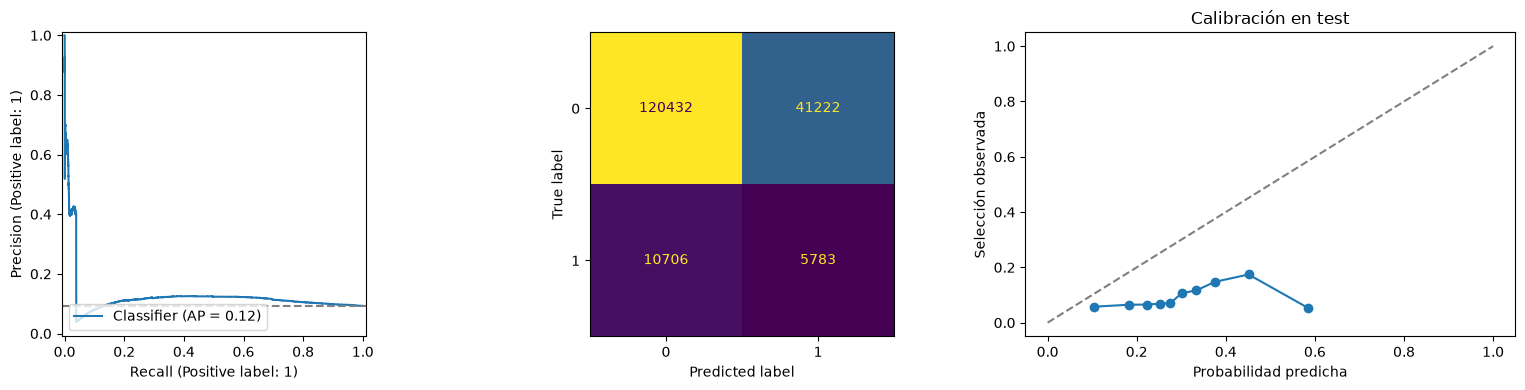

,dimension,valor,filas,prevalencia,precision,recall,average_precision,roc_auc,brier,log_loss,alertas,cobertura
0,mes,2024-10,6733,0.258577,0.467613,0.302700,0.426817,0.675350,0.176272,0.529092,1127,0.167385
1,mes,2024-11,112503,0.088060,0.164872,0.315333,0.161072,0.623642,0.117948,0.405074,18948,0.168422
2,mes,2024-12,58907,0.082180,0.079168,0.440405,0.102161,0.496482,0.187823,0.553874,26930,0.457161
3,sector,Municipalidades,75592,0.103186,0.201151,0.232949,0.174370,0.622646,0.117086,0.400513,9033,0.119497
4,sector,FFAA,8350,0.172216,0.360000,0.431850,0.323973,0.673109,0.152640,0.485356,1725,0.206587
5,sector,Obras Públicas,2360,0.194492,0.277972,0.346405,0.275675,0.608123,0.168413,0.516534,572,0.242373
6,sector,"Gob. Central, Universidades",8800,0.178409,0.269650,0.299363,0.286036,0.628910,0.152840,0.482357,1743,0.198068
7,sector,Salud,61291,0.073388,0.141362,0.534460,0.192354,0.711763,0.123902,0.419830,17006,0.277463
8,sector,Otros,5641,0.093955,0.146586,0.413208,0.138146,0.566867,0.138120,0.455444,1494,0.264847
9,sector,NA,15917,0.008796,0.004426,0.485714,0.043834,0.254815,0.329177,0.851430,15363,0.965194


CodigoUnidad           0.208046
CodigoProductoONU      0.144412
sector                 0.000000
Tipo                   0.000135
RegionUnidad           0.000000
Moneda Adquisicion     0.000000
Moneda de la Oferta    0.000000
UnidadMedida           0.000567
Rubro1                 0.000415
Rubro2                 0.003009
Rubro3                 0.027461
CodigoProveedor        0.201754
Name: proporción no vista en ajuste, dtype: float64

In [4]:
display(pd.DataFrame(informe['test']).T.drop(columns='matriz_confusion'))
display(informe['bootstrap_por_licitacion'])
pred = pd.read_parquet(RUN / 'predicciones_test.parquet')
ganador = informe['decision']['candidato']
umbral = informe['decision']['umbral']
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(16,4))
PrecisionRecallDisplay.from_predictions(pred.y, pred[ganador], ax=axes[0])
axes[0].axhline(pred.y.mean(), color='gray', linestyle='--')
ConfusionMatrixDisplay.from_predictions(pred.y, pred[ganador] >= umbral, ax=axes[1], colorbar=False)
cal = pd.read_csv(RUN / 'calibracion_test.csv').sort_values('predicha')
axes[2].plot(cal.predicha, cal.observada, marker='o')
axes[2].plot([0,1], [0,1], linestyle='--', color='gray')
axes[2].set(xlabel='Probabilidad predicha', ylabel='Selección observada', title='Calibración en test')
fig.tight_layout()
plt.show()
diagnosticos = pd.DataFrame(json.loads((RUN / 'diagnosticos_test.json').read_text(encoding='utf-8')))
display(diagnosticos.drop(columns='matriz_confusion'))
display(pd.Series(informe['tasas_categorias_no_vistas_test'], name='proporción no vista en ajuste'))

## Inferencia sobre campos crudos reales
El ejemplo contiene ofertas del conjunto de prueba; no se crean ofertas sintéticas. Se carga el artefacto guardado y se aplica la misma función de preparación que en entrenamiento.

In [5]:
import joblib
artefacto = joblib.load(RUN / 'modelo_candidato.joblib')
entrada = pd.DataFrame(json.loads((RUN / 'ejemplo_entrada.json').read_text(encoding='utf-8')))
salida = predict(artefacto, entrada)
guardadas = pd.read_csv(RUN / 'ejemplo_predicciones.csv')
np.testing.assert_allclose(salida.probabilidad, guardadas.probabilidad)
display(pd.concat([entrada[['CodigoUnidad','CodigoProductoONU','CodigoProveedor']], salida], axis=1))
display(Markdown(chr(10).join(['### Limitaciones pendientes', ''] + ['- ' + x for x in informe['limitaciones']])))
print('Promovido:', informe['promovido'])

,CodigoUnidad,CodigoProductoONU,CodigoProveedor,probabilidad,prediccion
0,3305,51141505,1261270,0.082142,0
1,3305,51141505,24141,0.284627,0
2,3305,51141505,269948,0.303919,0
3,3305,51141505,1426099,0.204518,0
4,3305,51141505,103860,0.380362,1
5,3305,51141505,1773777,0.153831,0
6,3305,51141502,103860,0.369503,1
7,3305,51141502,1426099,0.197534,0
8,3305,51141502,269948,0.289375,0
9,3305,51141502,24141,0.276521,0


### Limitaciones pendientes

- Todo 2024 ya fue explorado: test temporal retrospectivo, no confirmatorio independiente.
- Estado y fecha de adjudicación son proxies; faltan snapshots y fecha verificable de resultado efectivo.
- Los campos del CSV podrían haber cambiado después del envío; no se acredita disponibilidad histórica.
- La población son procesos adjudicados con fechas válidas y resultado disponible al corte, no todas las licitaciones.
- Muestra por licitación y límite de ajuste documentados; no se usó sobremuestreo 50/50.
- Bootstrap condicionado a la muestra y al modelo ajustado: no captura toda la incertidumbre de entrenamiento.
- V0.2 usa otra población y partición: sus métricas no permiten declarar una mejora directa.
- No se construyeron tasas históricas de éxito sin verificar fechas efectivas de adjudicación.

Promovido: False
